# Employee Attrition Analytics — Exploratory Data Analysis (EDA)

## 1. Introduction

### Project Overview

This notebook forms the second stage of the Employee Attrition Analytics project, following the Extract, Transform and Load (ETL) process.

The project uses the publicly available **IBM HR Analytics Employee Attrition & Performance** synthetic dataset to examine key trends related to organisational turnover.

The cleaned dataset cosists of **1,470 employee records and 35 columns**, including three custom features generated during preprocessing.

The main objective of this analysis is to uncover significant patterns in employee attrition and deliver actionable insights that drive data-informed workforce planning and targeted retention strategies.

### Business Problem

Staff turnover introduces replacement costs, operational disruption, and reduced organizational effectiveness. While analyzing attrition variances across employee demographics helps HR teams identify priority areas for deeper study, observed associations must not be interpreted as causal drivers of turnover.

### EDA Objectives

To guide strategy, this analysis will evaluate five key business questions:

1. **Overall Attrition:** What proportion of total staff have left the company?
2. **Department and Job Role:** How do attrition rates vary across departments and job roles?
3. **Overtime:** Does working extra hours correlate with higher employee attrition?
4. **Job Satisfaction:** How does attrition vary across job satisfaction levels?
5. **Employee Tenure:** Are newer hires departing at higher rates than long-tenured employees?

### Analytical Approach

The notebook will utilise:

- Descriptive statistics to summarise the workforce.
- Segmented attrition rates to compare employee categories.
- Python visualisations to highlight key distributions and correlations.
- Chi-square tests of independence to investigate realationships across categorical variables.
- Business interpretations to detail the relevance and constraints of findings.

Outputs from this notebook will directly feed into two Tableau dashboards: **Workforce Overview** and **Attrition Drivers**.

### Ethical Considerations

**Privacy & Protection:** The dataset is purely synthetic and free of real employee identities, though sensitive workforce traits are analyzed responsibly.

**Aggregated Reporting:** Insights are reported at a group level, and demographic data will not be applied toward biased employment actions.

**Analytical Integrity:** Correlation will not be presented as causation, and the inherent limits of synthetic data will be clearly acknowledged.


In [1]:
# Import the required Python libraries

# Data manipulation
import pandas as pd

# Data visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Statistical testing
from scipy.stats import chi2_contingency

# File paths
from pathlib import Path

# Set a consistent visualisation style
sns.set_theme(style="whitegrid")

print("EDA libraries imported successfully.")


EDA libraries imported successfully.


## 2. Loading the Cleaned Dataset

The exploratory analysis uses the processed dataset created in the ETL stage, rather than the original raw CSV.

Using the validated dataset ensures that all visualisations and statistical calculations are based on consistent data, including the engineered `Attrition_Flag`, `Age_Group` and `Tenure_Group` features.

The dataset is loaded from the versioned `data/cleaned/v1/` directory to support reproducibility.

In [6]:
print(Path.cwd())

c:\Users\munta\OneDrive\employee-attrition-analytics\Employee-Attrition-Analytics\jupyter_notebooks\jupyter_notebooks


In [7]:
# Define the path to the cleaned dataset
file_path = Path("../../data/cleaned/v1/employee_attrition_cleaned.csv")

# Load the cleaned dataset
df = pd.read_csv(file_path)

# Verify that the dataset loaded correctly
print("Dataset shape:", df.shape)
print("Total employees:", len(df))
print("Total employees who left:", df["Attrition_Flag"].sum())

# Show the first five rows
display(df.head())


Dataset shape: (1470, 35)
Total employees: 1470
Total employees who left: 237


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeNumber,EnvironmentSatisfaction,...,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Attrition_Flag,Age_Group,Tenure_Group
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,2,...,8,0,1,6,4,0,5,1,36-45,6-10 years
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,2,3,...,10,3,3,10,7,1,7,0,46-55,6-10 years
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,4,4,...,7,3,3,0,0,0,0,1,36-45,0-2 years
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,5,4,...,8,3,3,8,7,3,0,0,26-35,6-10 years
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,7,1,...,6,3,3,2,2,2,2,0,26-35,0-2 years


## 3. Overall Employee Attrition Analysis

### Business Question 1: What proportion of employees have left the organisation?

The overall employee attrition rate provides a baseline for understanding how well the organisation retains its employees.

In this dataset, attrition refers to employees leaving an organisation. The `Attrition` column marks employees who have left as (`Yes`) and those who stayed as (`No`).

The attrition rate is calculated as:

**Attrition Rate (%) = (Number of Employees Who Left / Total Employees) × 100**

This analysis will count the number of employees in each attrition category and their pencentages then visualise the distribution using a bar chart.

The findings will serve as a starting point for comparing attrition patterns across departments, job roles and other employee characteristics.

In [8]:
# Calculate employees in each attrition category
attrition_counts = df["Attrition"].value_counts()

# Count the percentage of employees in each category
attrition_percentages = (
    df["Attrition"].value_counts(normalize=True) * 100
)

# Display the results
print("Employee Attrition Counts:")
print(attrition_counts)

print("\nEmployee Attrition Percentages:")
print(attrition_percentages.round(2))

# Calculate the overall attrition rate
overall_attrition_rate = df["Attrition_Flag"].mean() * 100

print(f"\nOverall Attrition Rate: {overall_attrition_rate:.2f}%")


Employee Attrition Counts:
Attrition
No     1233
Yes     237
Name: count, dtype: int64

Employee Attrition Percentages:
Attrition
No     83.88
Yes    16.12
Name: proportion, dtype: float64

Overall Attrition Rate: 16.12%


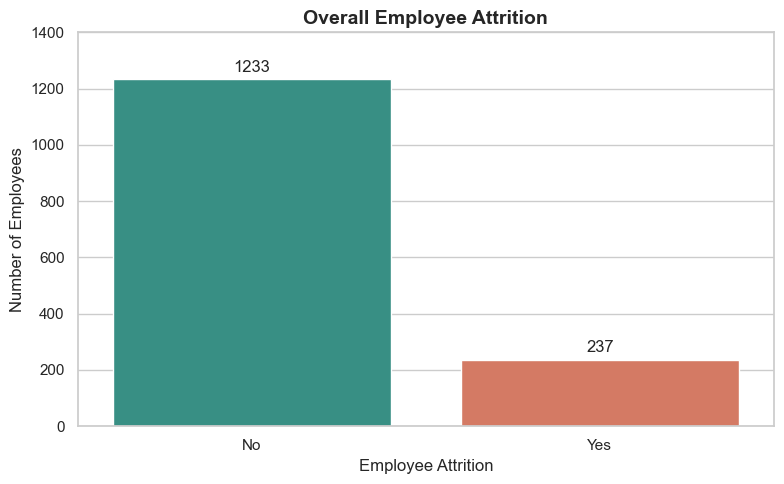

In [10]:
# Create a bar chart to visualize 
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="Attrition",
    order=["No", "Yes"],
    hue="Attrition",
    hue_order=["No", "Yes"],
    palette={"No": "#2A9D8F", "Yes": "#E76F51"},
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.title("Overall Employee Attrition", fontsize=14, fontweight="bold")
plt.xlabel("Employee Attrition")
plt.ylabel("Number of Employees")
plt.ylim(0, 1400)

plt.tight_layout()
plt.show()


### Findings and Business Interpretation

The analysis identified **237 employees (16.12%)** who left the organisation, compared with **1,233 employees (83.88%)** who stayed.

The bar chart confirms that retained personnel (the non-attrition group) make up the vast majority of the dataset. Approximately one in six employee records is classified as having experienced attrition.

**Business Implications**

The overall attrition rate of 16.12% provides a reference point for comparing employee teams, departments, job roles and working conditions. Identifying groups above this baseline helps pinpoint operational areas may warrant closer HR review.

However, the findings do not explain why employees left, and because the dataset does not specify an observation period, this figure should not be interpreted as an annual turnover rate.

**Limitations**

The dataset contains synthetic employee records, so findings should not be applied to real organisations without further supporting evidence.

**Key Finding:** The overall employee attrition rate is 16.12%, providing a reference point for subsequent analysis.

## 4. Department and Job Role Attrition Analysis

### Business Question 2: Which departments and job roles have the highest employee attrition rates?

Employee attrition may differ by departments and job role, as employees in different groups can have varying work environments, responsibilities and employment conditions.

This analysis aims to compare attrition rates across departments and job roles with the organisation-wide benchmark of 16.12%.

Instead of only looking at how many employees left the company, this analysis will calculate the **attrition rate for each group**. This makes it easier to compare departments and job roles of different sizes, in a more meaningful way.

The results may help HR teams spot areas that may need further review and guide focused employee retention strategies.

However, differences in attrition rates alone do not explain the reasons behind employee departures.

In [11]:
# Group employees by department and calculate attrition statistics
department_attrition = (
    df.groupby("Department")
    .agg(
        Total_Employees=("EmployeeNumber", "count"),
        Employees_Left=("Attrition_Flag", "sum"),
        Attrition_Rate=("Attrition_Flag", "mean")
    )
    .reset_index()
)

# Convert the attrition rate into a percentage
department_attrition["Attrition_Rate"] = (
    department_attrition["Attrition_Rate"] * 100
).round(2)

# Sort departments from highest to lowest attrition rate
department_attrition = department_attrition.sort_values(
    by="Attrition_Rate",
    ascending=False
)

display(department_attrition)


,Department,Total_Employees,Employees_Left,Attrition_Rate
2,Sales,446,92,20.63
0,Human Resources,63,12,19.05
1,Research & Development,961,133,13.84


### Department Attrition Rate Visualisation

A horizontal bar chart is used to compare attrition rates across departments.

Attrition percentages are more useful than raw departure counts for this comparison because departments differ in workforce sizes.

A reference line marking the overall organisational attrition rate of 16.12% provides a benchmark, showing which departments are above or below the baseline.

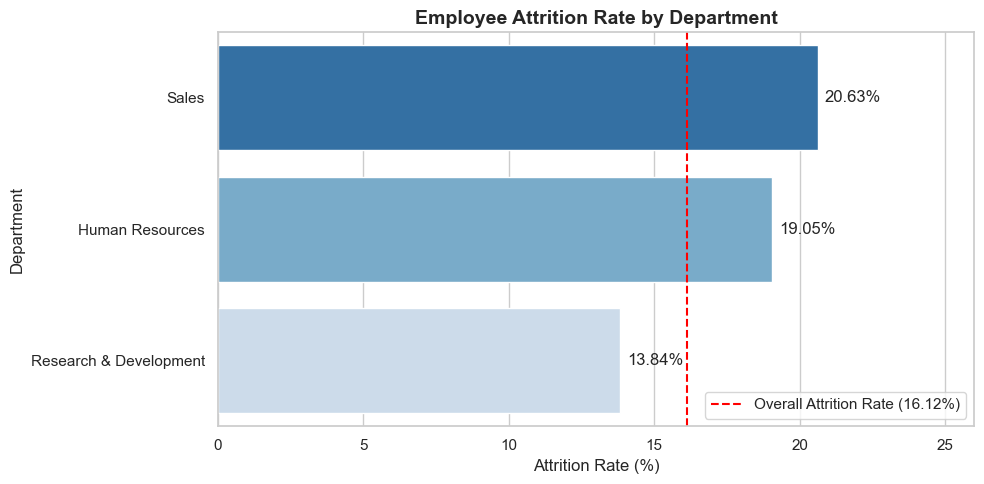

In [12]:
# Make a horizontal bar chart of department attrition rates
plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=department_attrition,
    x="Attrition_Rate",
    y="Department",
    hue="Department",
    palette="Blues_r",
    legend=False
)

# Add the overall attrition rate as a reference line
plt.axvline(
    x=overall_attrition_rate,
    color="red",
    linestyle="--",
    label=f"Overall Attrition Rate ({overall_attrition_rate:.2f}%)"
)

# Show percentage labels
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=5)

plt.title("Employee Attrition Rate by Department",
          fontsize=14, fontweight="bold")
plt.xlabel("Attrition Rate (%)")
plt.ylabel("Department")
plt.xlim(0, 26)
plt.legend()

plt.tight_layout()
plt.show()


### Department Attrition: Findings and Business Interpretation

The analysis reveals differences in employee attrition rates across the three departments.

**Key Findings**

- **Sales:** Had the highest attrition rate at **20.63%**, with 92 of 446 employees leaving. This is 4.51 percentage points above the organisational wide-rate of 16.12%.
- **Human Resources:** Had an attrition rate of **19.05%**, with 12 of 63 employees leaving the organisation. This is 2.93 percentage points above the overall baseline.
- **Research & Development:** Recorded the lowest attrition rate at **13.84%**, with 133 of 961 employees leaving. Despite it having the largest number of leavers, its attrition rate stayed below the overall organisational rate.

**Business Implications**

The Sales department may be a priority for further investigation as it has the highest proportion of employees recorded as leaving.

Human Resources was also above the overall attrition rate. Although its workforce is smaller, a relatively small number of departures can have a noticeable effect on its percentage.

Research & Development illustrated why comparing attrition rates, rather that departure counts alone, is useful when departments differ in size.

These findings could help HR teams give priority to  further investigation into the experiences of employees, workload practices as well as and retention.

**Analytical Limitations**

These descriptive results do not explain why employees left. More information would be needed to assess whether working conditions, management practices, or other factors are related to employee attrition. 

Moreover, the dataset is artificially generated (synthetic), so the findings should not be generalised to real organisations.

**Key Insight:** Sales has the highest departmental attrition rate at 20.63%, which was 4.51 percentage above the overall organisational baseline.